# Sprint 2: Classificação e agrupamento das causas de morte

Objetivo:
Mapear a coluna de causas básicas (`CAUSABAS` baseada na CID-10) para identificar quais são os maiores gargalos de mortalidade no município. Para evitar uma massa excessiva de dados genéricos, aplicamos uma função de categorização detalhada que isola capítulos críticos (como doenças circulatórias, neoplasias, respiratórias, endócrinas/diabetes e causas mal definidas).

In [2]:
import pandas as pd

colunas_necessarias = ['CODMUNRES', 'CAUSABAS']
df = pd.read_csv('../data/processed/sim_sc_processado.csv', usecols=colunas_necessarias)

df_ararangua = df[df['CODMUNRES'].astype(str).str.contains('420140', na=False)]

print("10 maiores causas básicas de óbito em Araranguá (Código CID-10):")
print(df_ararangua['CAUSABAS'].value_counts().head(10))

10 maiores causas básicas de óbito em Araranguá (Código CID-10):
CAUSABAS
I219    1105
I64      631
410X     382
436X     316
C349     308
J189     284
B342     276
R99      270
E149     256
J449     236
Name: count, dtype: int64


In [ ]:
def classificar_evitabilidade_detalhada(causa):
    if pd.isna(causa):
        return 'Mal Definidos / Ignorados'
    
    causa_str = str(causa).upper()
    
    # Doenças infecciosas e parasitárias (Capítulo A e B)
    if causa_str.startswith(('A', 'B')):
        return 'Infecciosas e Parasitárias'
    
    # Neoplasias / Cânceres (Capítulo C e D00-D48)
    elif causa_str.startswith(('C', 'D')):
        return 'Neoplasias (Tumores)'
    
    # Endócrinas, nutricionais e metabólicas - Ex: Diabetes (Capítulo E)
    elif causa_str.startswith('E'):
        return 'Endócrinas e Metabólicas (ex: Diabetes)'
    
    # Doenças do aparelho circulatório (Capítulo I)
    elif causa_str.startswith('I'):
        return 'Doenças do Aparelho Circulatório'
    
    # Doenças do aparelho respiratório (Capítulo J)
    elif causa_str.startswith('J'):
        return 'Doenças do Aparelho Respiratório'
    
    # Doenças do aparelho digestivo (Capítulo K)
    elif causa_str.startswith('K'):
        return 'Doenças do Aparelho Digestivo'
    
    # Causas externas - acidentes e violências (Capítulo V, W, X, Y)
    elif causa_str.startswith(('V', 'W', 'X', 'Y')):
        return 'Causas Externas (Acidentes/Violências)'
    
    # Sintomas, sinais e achados anormais - Mal definidos (Capítulo R)
    elif causa_str.startswith('R'):
        return 'Sintomas e Sinais Mal Definidos'
    
    else:
        return 'Outras Causas Específicas'

df_ararangua['GRUPO_DETALHADO'] = df_ararangua['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

print("Resumo dos grupos de óbito em Araranguá:")
print(df_ararangua['GRUPO_DETALHADO'].value_counts())

Resumo Detalhado dos Grupos de Óbito em Araranguá:
GRUPO_DETALHADO
Outras Causas Específicas                  4959
Doenças do Aparelho Circulatório           3640
Neoplasias (Tumores)                       2067
Doenças do Aparelho Respiratório           1336
Causas Externas (Acidentes/Violências)     1226
Infecciosas e Parasitárias                  676
Endócrinas e Metabólicas (ex: Diabetes)     648
Doenças do Aparelho Digestivo               534
Sintomas e Sinais Mal Definidos             522
Name: count, dtype: int64


C:\Users\goula\AppData\Local\Temp\ipykernel_7080\2808539879.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


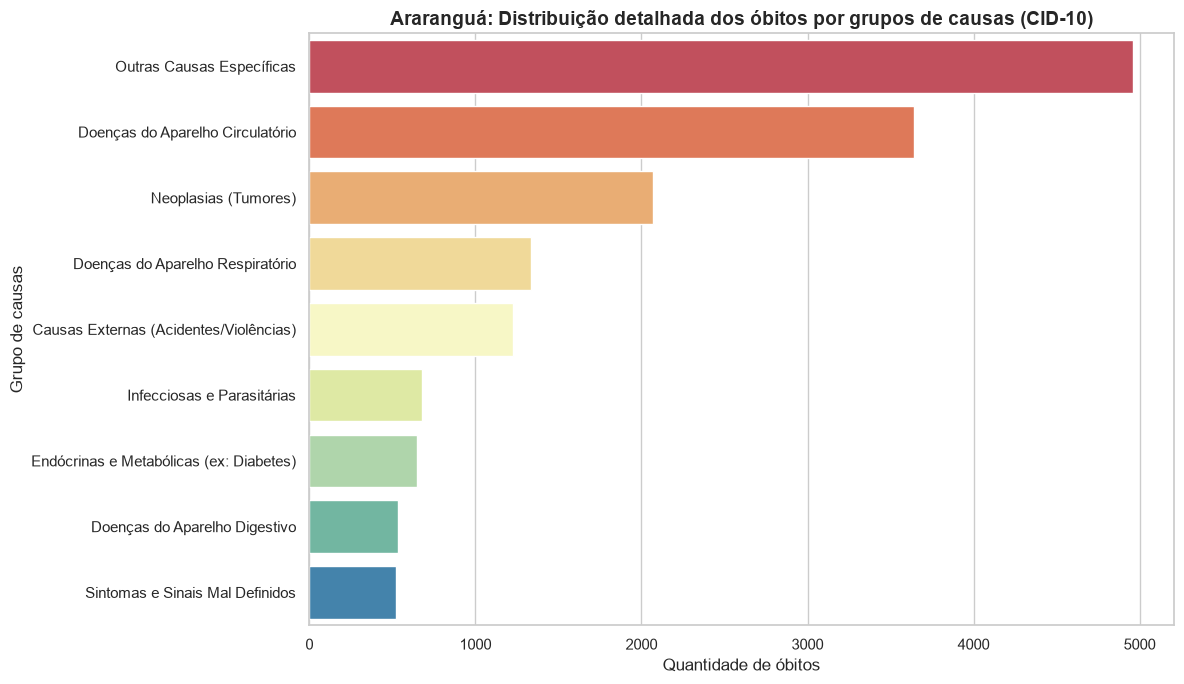

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))
ax = sns.countplot(
    data=df_ararangua, 
    y='GRUPO_DETALHADO', 
    order=df_ararangua['GRUPO_DETALHADO'].value_counts().index,
    palette='Spectral'
)

plt.title('Araranguá: Distribuição detalhada dos óbitos por grupos de causas (CID-10)', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de óbitos', fontsize=12)
plt.ylabel('Grupo de causas', fontsize=12)

plt.tight_layout()
plt.show()